# Power Curve Analysis
## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## Reading in the Datasets

In [2]:
# load in turbine and met masts datasets
scada = pd.read_parquet('../../data/cleaned/scada_data.parquet')
metmasts = pd.read_parquet('../../data/cleaned/metmasts_data.parquet')
reference = pd.read_parquet('../../data/cleaned/reference_power_curve.parquet')

## LiDAR Correction

In [ ]:
lidar_correction = pd.DataFrame({
    "bin": [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, 10.5, 11.5, 12.5, 13.5, 14.5, 15.5],
    "bias": [-0.148492, -0.042985, 47]
})

### Creating List of All Turbines

In [3]:
turbines = scada['turbine'].unique()

## Generating Power Curves

In [4]:
def corrected_wind_speed(wind_speed, air_density, ws0 = 7, ws1 = 12, ex0 = 1/3, ex1 = 2/3, standard = 1.225):
    frac = np.clip((wind_speed - ws0) / (ws1 - ws0), 0, 1)
    exponent = ex0 + frac * (ex1 - ex0)
    
    return wind_speed * (air_density / standard) ** exponent

In [155]:
scada['corrected_ws'] = corrected_wind_speed(scada['wind_speed'], scada['air_density'], standard = 1.050817)
reference['corrected_ref_ws'] = corrected_wind_speed(reference['wind_speed_ref'], reference['air_density_ref'], standard = 1.050817)

In [156]:
# Filtering out cases where the turbine was offline
scada = scada[~((scada['KPI_real_power_ac'] == 0) & (scada['real_power_ac'].isna()))]

In [25]:
def avg_power_curve(df_full, turbine, p = 'M', cutin = 3, rated = 15, width = 0.5, wind_speed = 'corrected_ws', min_count = 1, 
                    exclude_target_from_fleet = False):
    # filter to the given wind-speed range.
    valid_ws = (df_full[wind_speed].ge(cutin) & df_full[wind_speed].le(rated))
    df_all = df_full.loc[valid_ws].copy()

    # create a common period and bin definition.
    df_all['period'] = df_all['utc'].dt.to_period(p)
    n_bins = int(np.ceil((rated - cutin) / width))
    df_all['bin'] = np.floor((df_all[wind_speed] - cutin) / width).astype('int64').clip(0, n_bins - 1)

    # target turbine's period-by-bin averages.
    df = df_all.loc[df_all['turbine'].eq(turbine)].copy()

    bin_means = (df.groupby(['period', 'bin'], observed = True).agg(mean_real_power = ('KPI_real_power_ac', 'mean'),
                                                                    mean_theoretical_power = ('KPI_theoretical_power', 'mean'),
                                                                    n = ('KPI_real_power_ac', 'count')).reset_index())

    # fleet reference: mean measured power for each period and bin.
    fleet_data = df_all

    if exclude_target_from_fleet:
        fleet_data = fleet_data.loc[~fleet_data['turbine'].eq(turbine)]

    fleet_means = (fleet_data.groupby(['period', 'bin'], observed = True).agg(mean_fleet_power = ('KPI_real_power_ac', 'mean'),
                                                                              n_fleet = ('KPI_real_power_ac', 'count'),
                                                                              n_fleet_turbines = ('turbine', 'nunique')).reset_index())

    # join the reference values by their matching period and bin.
    bin_means = bin_means.merge(fleet_means, on = ['period', 'bin'], how = 'left', validate = 'one_to_one')

    # wind-speed bin midpoint.
    bin_means[wind_speed] = (cutin + (bin_means['bin'] + 0.5) * width)

    # correct the midpoint for a potentially partial final bin.
    bin_means[wind_speed] = np.minimum(bin_means[wind_speed], rated)

    bin_means['turbine'] = turbine

    # calculate relative differences; invalid references become NaN.
    valid_target = (bin_means['n'].ge(min_count) & bin_means['mean_real_power'].notna())
    valid_theoretical = (valid_target & bin_means['mean_theoretical_power'].gt(0))
    valid_fleet = (valid_target & bin_means['mean_fleet_power'].gt(0))

    bin_means['perc_diff_theoretical'] = np.nan
    bin_means.loc[valid_theoretical, 'perc_diff_theoretical'] = (bin_means.loc[valid_theoretical, 'mean_real_power']
                                                                 / bin_means.loc[valid_theoretical, 'mean_theoretical_power'] - 1)

    bin_means['perc_diff_fleet'] = np.nan
    bin_means.loc[valid_fleet, 'perc_diff_fleet'] = (bin_means.loc[valid_fleet, 'mean_real_power']
                                                     / bin_means.loc[valid_fleet, 'mean_fleet_power'] - 1)

    # average the bin-level relative differences within each period.
    bin_means['avg_perc_diff_theoretical'] = (bin_means.groupby('period', observed = True)['perc_diff_theoretical'].transform('mean'))
    bin_means['avg_perc_diff_fleet'] = (bin_means.groupby('period', observed = True)['perc_diff_fleet'].transform('mean'))

    # number of valid bins contributing to each period's average.
    bin_means['n_valid_theoretical_bins'] = (bin_means.groupby('period', observed = True)['perc_diff_theoretical'].transform('count'))
    bin_means['n_valid_fleet_bins'] = (bin_means.groupby('period', observed = True)['perc_diff_fleet'].transform('count'))

    return bin_means

### Summarizing Every Turbine

In [166]:
summaries = []

for w in turbines:
    res = avg_power_curve(scada, w, p = 'M', cutin = 4, rated = 15, width = 0.5)

    # keep one row per period and turbine
    summary = res[['period', 'turbine', 'avg_perc_diff_theoretical', 'avg_perc_diff_fleet', 'n_valid_theoretical_bins',
                   'n_valid_fleet_bins']].drop_duplicates(subset = ['period', 'turbine'])

    summaries.append(summary)

turbine_summary = pd.concat(summaries, ignore_index = True)

turbine_summary = turbine_summary.sort_values(['period', 'turbine']).reset_index(drop = True)

In [167]:
turbine_summary.shape

(409, 6)

In [168]:
turbine_summary['avg_perc_diff_theoretical'].describe()

count    409.000000
mean       0.026137
std        0.089897
min       -0.429029
25%       -0.015821
50%        0.035486
75%        0.075825
max        0.225042
Name: avg_perc_diff_theoretical, dtype: float64

In [169]:
turbine_summary.sort_values('avg_perc_diff_theoretical', ascending = False)

,period,turbine,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
16,2026-01,WTG167,0.225042,0.145317,22,22
143,2026-04,WTG154,0.219716,0.124757,22,22
4,2026-01,WTG154,0.216523,0.138651,22,22
31,2026-01,WTG182,0.205799,0.132230,22,22
155,2026-04,WTG167,0.200622,0.109107,22,22
...,...,...,...,...,...,...
191,2026-05,WTG157,-0.374360,-0.385451,22,22
371,2026-09,WTG157,-0.386089,-0.385771,22,22
281,2026-07,WTG157,-0.415128,-0.417933,22,22
236,2026-06,WTG157,-0.424238,-0.425647,22,22


In [20]:
turbine_summary['avg_perc_diff_fleet'].describe()

count    409.000000
mean       0.003589
std        0.180932
min       -0.708515
25%       -0.077534
50%        0.031457
75%        0.126005
max        0.345695
Name: avg_perc_diff_fleet, dtype: float64

In [21]:
# All expected turbine-month combinations
all_periods = scada["utc"].dt.to_period("M").dropna().unique()

expected = pd.MultiIndex.from_product(
    [all_periods, turbines],
    names=["period", "turbine"]
).to_frame(index=False)

# Identify missing combinations
missing = expected.merge(
    turbine_summary[["period", "turbine"]],
    on=["period", "turbine"],
    how="left",
    indicator=True
)

missing = missing[missing["_merge"] == "left_only"].drop(
    columns="_merge"
)

print(f"Expected rows: {len(expected)}")
print(f"Actual rows: {len(turbine_summary)}")
print(f"Missing rows: {len(missing)}")

print(missing.sort_values(["period", "turbine"]).to_string(index=False))

Expected rows: 423
Actual rows: 409
Missing rows: 14
 period turbine
2026-02  WTG169
2026-03  WTG169
2026-04  WTG169
2026-04  WTG183
2026-05  WTG169
2026-05  WTG183
2026-06  WTG169
2026-06  WTG183
2026-07  WTG169
2026-07  WTG183
2026-08  WTG169
2026-08  WTG183
2026-09  WTG169
2026-09  WTG183


### Analyzing WTG159

In [34]:
result = avg_power_curve(scada, 'WTG179', p = 'M', cutin = 3, rated = 15, width = 0.5)

In [35]:
result[result['period'] == '2026-02']

,period,bin,mean_real_power,mean_theoretical_power,n,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
24,2026-02,0,14.630977,0.000000,323,18.888310,15440,46,3.25,WTG179,NaN,-0.225395,0.186226,0.040771,23,24
25,2026-02,1,56.103282,10.314452,243,55.283226,13216,46,3.75,WTG179,4.439289,0.014834,0.186226,0.040771,23,24
26,2026-02,2,127.834546,130.560762,233,116.629935,11098,46,4.25,WTG179,-0.020881,0.096070,0.186226,0.040771,23,24
27,2026-02,3,203.636708,196.466513,198,193.430019,9769,46,4.75,WTG179,0.036496,0.052767,0.186226,0.040771,23,24
28,2026-02,4,304.585239,294.995525,168,282.654018,8573,46,5.25,WTG179,0.032508,0.077590,0.186226,0.040771,23,24
29,2026-02,5,400.331048,393.906001,163,393.037776,7455,46,5.75,WTG179,0.016311,0.018556,0.186226,0.040771,23,24
30,2026-02,6,479.289011,522.720170,174,523.209515,6261,46,6.25,WTG179,-0.083087,-0.083944,0.186226,0.040771,23,24
31,2026-02,7,619.480633,668.525078,142,674.538823,5319,46,6.75,WTG179,-0.073362,-0.081623,0.186226,0.040771,23,24
32,2026-02,8,829.316800,824.963234,126,848.027170,4329,46,7.25,WTG179,0.005277,-0.022063,0.186226,0.040771,23,24
33,2026-02,9,968.348401,1008.559383,95,1017.195682,3716,46,7.75,WTG179,-0.039870,-0.048022,0.186226,0.040771,23,24


In [28]:
reference

,model,rated_power_ref,air_density_ref,wind_speed_ref,power_ref,ti_class,corrected_ref_ws
0,GE_2_85MW_103mRD,2850,1.020,3.0,1,normal,2.970382
1,GE_2_85MW_103mRD,2850,1.020,3.5,7,normal,3.465445
2,GE_2_85MW_103mRD,2850,1.020,4.0,63,normal,3.960509
3,GE_2_85MW_103mRD,2850,1.020,4.5,130,normal,4.455573
4,GE_2_85MW_103mRD,2850,1.020,5.0,210,normal,4.950636
...,...,...,...,...,...,...,...
490,GE_2_85MW_103mRD,2850,1.225,23.5,2850,normal,26.029982
491,GE_2_85MW_103mRD,2850,1.225,24.0,2850,normal,26.583811
492,GE_2_85MW_103mRD,2850,1.225,24.5,2850,normal,27.137640
493,GE_2_85MW_103mRD,2850,1.225,25.0,2850,normal,27.691470


In [29]:
month = result[result['period'] == '2026-07']
mean_density = month['air_density'].mean()

reference = reference[
    np.isclose(reference['air_density_ref'], mean_density, atol = .1) & reference['ti_class'].astype(str).str.strip().str.lower().eq('normal')
].copy()

plt.figure(figsize = (10, 5))
plt.plot(month['corrected_ws'], month['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
plt.plot(month['corrected_ws'], month['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
plt.plot(reference['wind_speed_ref'], reference['power_ref'], color = 'black')
plt.xlim(3, 15)
plt.legend()
plt.xlabel('Wind Speed')
plt.ylabel('Mean Power Output')
plt.title('Mean Power Output by Binned Wind Speed')
plt.grid(alpha = 0.3)
plt.show()

KeyError: 'air_density'

In [36]:
ws_ref = np.sort(ref["wind_speed"].unique())
ref_std = pd.DataFrame({"wind_speed": ws_ref,
                        "power": interp(np.column_stack([ws_ref, np.full_like(ws_ref, 1.225)]))})

plt.scatter(meas["ws_corrected"], meas["power"], s=3, alpha=0.3, label="Measured (density-corrected)")
plt.plot(ref_std["wind_speed"], ref_std["power"], "k-", lw=2, label="Reference @ 1.225 kg/m³")
plt.xlabel("Corrected wind speed (m/s)"); plt.ylabel("Power"); plt.legend(); plt.show()

NameError: name 'ref' is not defined

In [170]:
result = avg_power_curve(scada, 'WTG167', p = 'M', cutin = 4, rated = 15, width = 0.5)

In [171]:
result[result['period'] == '2026-01']

,period,bin,mean_real_power,mean_theoretical_power,n,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
0,2026-01,0,128.052276,129.344064,345,129.380996,11238,47,4.25,WTG167,-0.009987,-0.010270,0.225042,0.145317,22,22
1,2026-01,1,222.194798,194.609442,202,199.517888,9611,47,4.75,WTG167,0.141747,0.113659,0.225042,0.145317,22,22
2,2026-01,2,340.848248,286.086001,121,294.132402,7335,47,5.25,WTG167,0.191419,0.158826,0.225042,0.145317,22,22
3,2026-01,3,481.481332,387.898519,66,405.805274,5433,47,5.75,WTG167,0.241256,0.186484,0.225042,0.145317,22,22
4,2026-01,4,709.958967,522.803836,49,551.427157,3958,47,6.25,WTG167,0.357983,0.287494,0.225042,0.145317,22,22
5,2026-01,5,899.208567,661.311145,50,728.742669,3026,47,6.75,WTG167,0.359736,0.233918,0.225042,0.145317,22,22
6,2026-01,6,1115.002559,837.462679,41,931.071129,2396,47,7.25,WTG167,0.331406,0.197548,0.225042,0.145317,22,22
7,2026-01,7,1489.404493,1011.507231,30,1131.268669,1894,47,7.75,WTG167,0.472461,0.316579,0.225042,0.145317,22,22
8,2026-01,8,1709.810513,1207.365531,26,1352.744519,1478,47,8.25,WTG167,0.416150,0.263957,0.225042,0.145317,22,22
9,2026-01,9,1861.996092,1384.334818,33,1577.780936,1147,47,8.75,WTG167,0.345048,0.180136,0.225042,0.145317,22,22


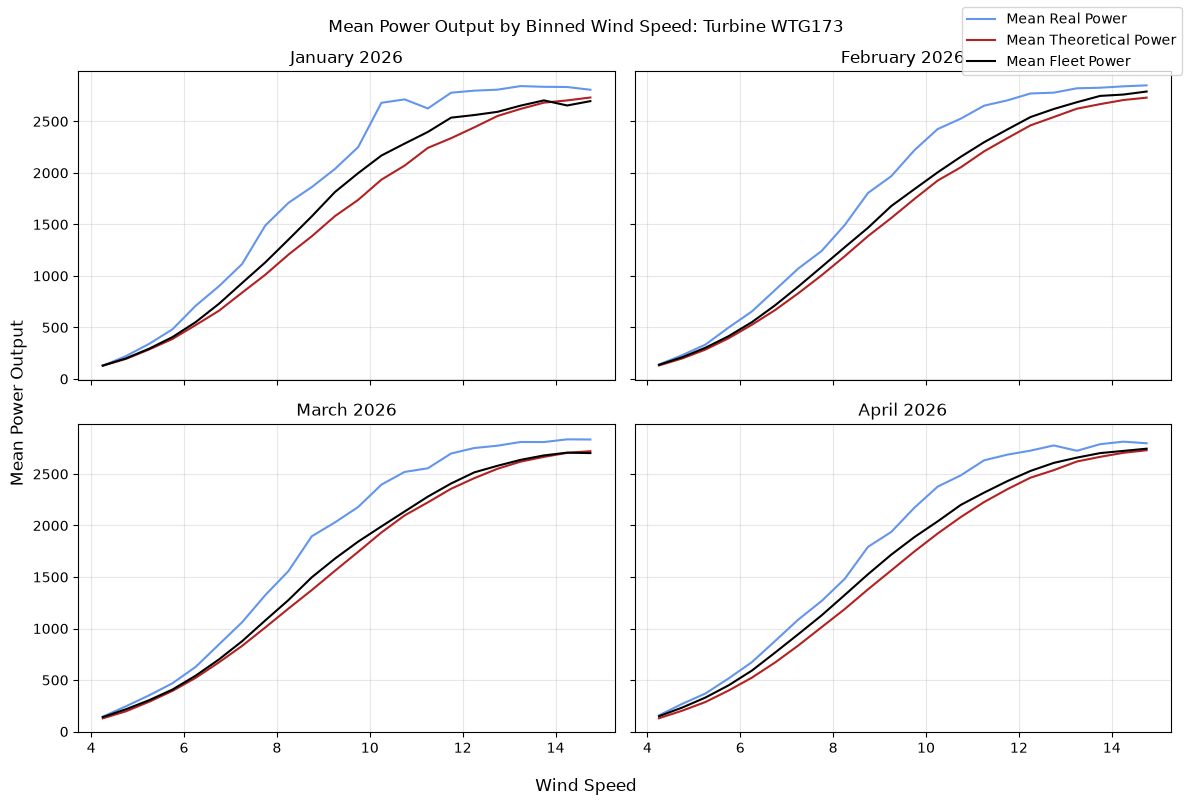

In [172]:
months = result['period'].unique()

fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    ax.plot(grp['corrected_ws'], grp['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
    ax.plot(grp['corrected_ws'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.plot(grp['corrected_ws'], grp['mean_fleet_power'], label = 'Mean Fleet Power', color = 'black')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG173')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()

In [131]:
scada2 = scada[~((scada['KPI_real_power_ac'] == 0) & (scada['real_power_ac'].isna()))]

In [140]:
result = avg_power_curve(scada2, 'WTG173', p = 'M', cutin = 4, rated = 15, width = 0.5)

In [141]:
summary = result[['period', 'avg_perc_diff_theoretical']].drop_duplicates()

summary

,period,avg_perc_diff_theoretical
0,2026-01,0.086570
22,2026-02,0.027833
44,2026-03,0.062166
66,2026-04,0.132511
88,2026-05,0.050602
110,2026-06,0.032265
132,2026-07,0.046242
154,2026-08,0.040764
176,2026-09,0.056466


In [134]:
result[result['period'] == '2026-01']

,period,bin,mean_real_power,mean_theoretical_power,n,mean_fleet_power,n_fleet,n_fleet_turbines,corrected_ws,turbine,perc_diff_theoretical,perc_diff_fleet,avg_perc_diff_theoretical,avg_perc_diff_fleet,n_valid_theoretical_bins,n_valid_fleet_bins
0,2026-01,0,43.682047,0.320553,349,41.869234,9477,47,3.25,WTG173,135.271029,0.043297,6.002456,0.025413,24,24
1,2026-01,1,96.416875,12.230398,205,77.600644,11774,47,3.75,WTG173,6.883380,0.242475,6.002456,0.025413,24,24
2,2026-01,2,175.917369,130.153128,144,129.380996,11238,47,4.25,WTG173,0.351618,0.359685,6.002456,0.025413,24,24
3,2026-01,3,263.574182,193.584148,100,199.517888,9611,47,4.75,WTG173,0.361548,0.321055,6.002456,0.025413,24,24
4,2026-01,4,374.668718,289.175115,73,294.132402,7335,47,5.25,WTG173,0.295646,0.273810,6.002456,0.025413,24,24
5,2026-01,5,533.297825,395.300619,54,405.805274,5433,47,5.75,WTG173,0.349094,0.314172,6.002456,0.025413,24,24
6,2026-01,6,684.188773,521.222664,47,551.427157,3958,47,6.25,WTG173,0.312661,0.240760,6.002456,0.025413,24,24
7,2026-01,7,813.009921,659.330561,38,728.742669,3026,47,6.75,WTG173,0.233084,0.115634,6.002456,0.025413,24,24
8,2026-01,8,1050.540560,826.419559,35,931.071129,2396,47,7.25,WTG173,0.271195,0.128314,6.002456,0.025413,24,24
9,2026-01,9,1288.601728,1016.087377,35,1131.268669,1894,47,7.75,WTG173,0.268200,0.139077,6.002456,0.025413,24,24


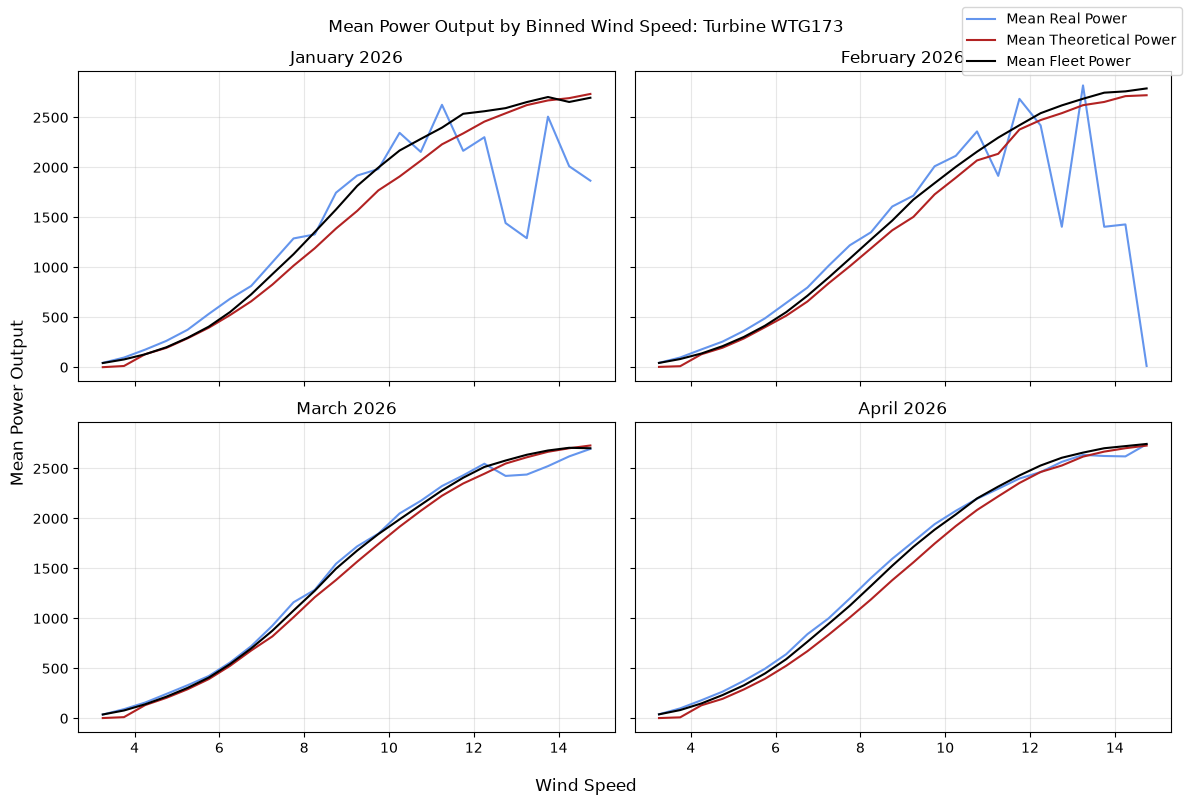

In [126]:
months = result['period'].unique()

fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    ax.plot(grp['corrected_ws'], grp['mean_real_power'], label = 'Mean Real Power', color = 'cornflowerblue')
    ax.plot(grp['corrected_ws'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.plot(grp['corrected_ws'], grp['mean_fleet_power'], label = 'Mean Fleet Power', color = 'black')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG173')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()

In [142]:
WTG173 = scada[(scada['turbine'] == 'WTG173') & (scada['corrected_ws'] >= 4.0) & (scada['corrected_ws'] <= 15.0)]

WTG173['period'] = WTG173['utc'].dt.to_period('M')

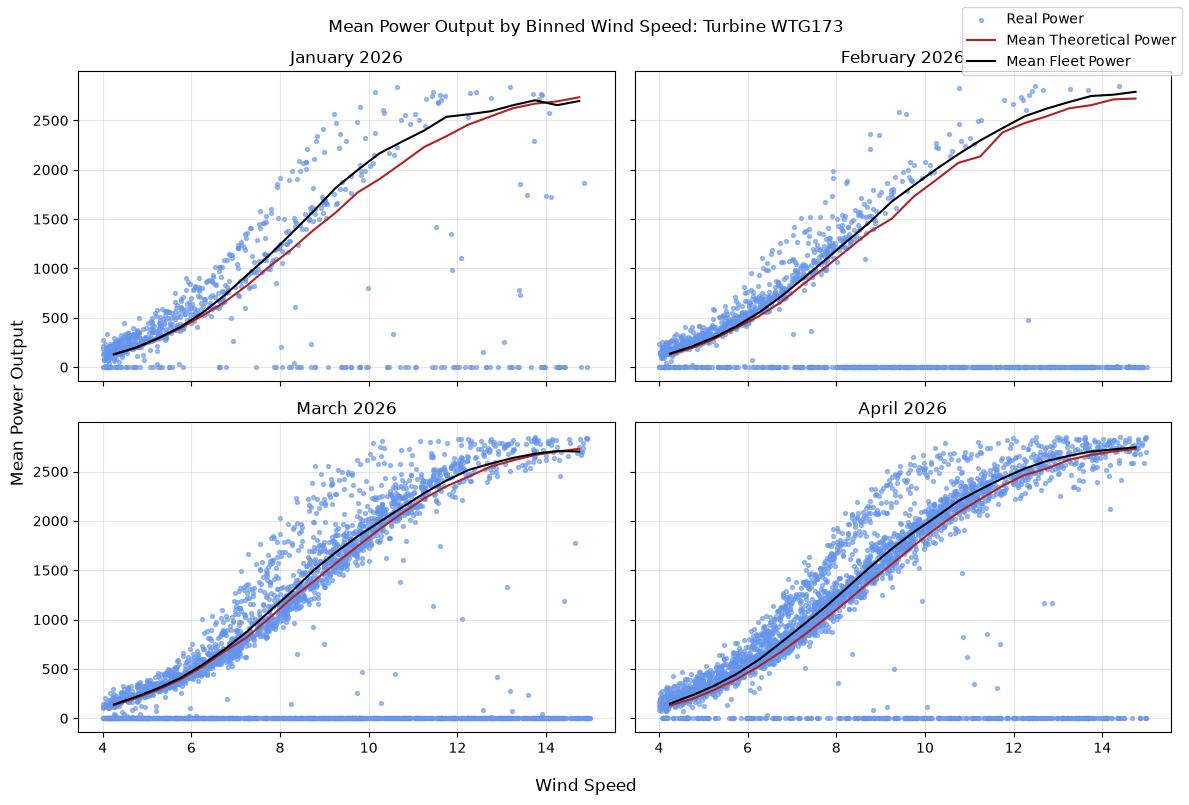

In [143]:
months = result['period'].unique()[:4]

fig, axes = plt.subplots(2, 2, figsize = (12, 8), sharex = True, sharey = True)

for ax, month in zip(axes.flat, months):
    grp = result[result['period'] == month]
    grp2 = WTG173[WTG173['period'] == month]
    ax.scatter(grp2['corrected_ws'], grp2['KPI_real_power_ac'], label = 'Real Power', color = 'cornflowerblue',s = 8, alpha = 0.6, zorder = 1)
    ax.plot(grp['corrected_ws'], grp['mean_theoretical_power'], label = 'Mean Theoretical Power', color = 'firebrick')
    ax.plot(grp['corrected_ws'], grp['mean_fleet_power'], label = 'Mean Fleet Power', color = 'black')
    ax.set_title(month.strftime('%B %Y'))
    ax.grid(alpha = 0.3)

fig.supxlabel('Wind Speed')
fig.supylabel('Mean Power Output')
fig.suptitle('Mean Power Output by Binned Wind Speed: Turbine WTG173')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc = 'upper right')

plt.tight_layout()
plt.show()